# Mining performance against the number of processes

`git2KG` mines a repository from two sources: the Git history of the repository
itself, and the GitHub API. Only the Git side is parallelised - `Dataloader`
splits the commit hashes into chunks and hands them to a process pool, so each
worker opens its own `pydriller` repository and parses its own diffs. The GitHub
side is a sequence of API calls whose runtime is set by the network and by
GitHub's rate limits, not by how many cores the machine has.

This notebook therefore measures the Git side alone. It runs the three
parallelised loaders - commits, edits and modified files - at several process
counts, repeats each configuration several times, and reports the distribution
rather than a single reading.

Three things are deliberately kept out of the measurement:

- **The clone.** `GitLoader` clones the repository into a temporary directory the
  first time a loader needs it. That is a one-off cost that belongs to neither
  the sequential nor the parallel path, so each run forces the clone through the
  public `local_repo_path()` before the clock starts.
- **The network.** The repository is cloned once into a local mirror up front,
  and every run clones from that mirror rather than from GitHub.
- **Persistence.** Runs use `NoOperationPersistenceManager`. A CSV persistence
  manager would add I/O to the measurement and, worse, would make the second run
  resume from where the first stopped and mine nothing at all.

One caveat to read the results with: `processes=1` is not a pool of one worker.
`Dataloader` dispatches it to the plain sequential generator instead, with no
pool and no chunking at all. The speedups below are therefore measured against
the sequential implementation a user actually gets, and they fold the cost of
starting and feeding a pool into the first parallel point.

In [6]:
import importlib
import json
import os
import platform
import random
import re
import sys
import time
from contextlib import redirect_stderr
from io import StringIO

import matplotlib.pyplot as plt
import pandas as pd
from git import Repo
from tqdm.auto import tqdm

from git2kg.dataloading import Dataloader
from git2kg.persistence import NoOperationPersistenceManager

## Configuration

The repository is the one the other demo notebooks use, so the numbers here can
be read next to the graphs they build. The process grid stops at the core count
of the machine: past that, workers only contend for the same cores.

In [4]:
REPO_URL = "https://github.com/tukaani-project/xz.git"
ORGANIZATION = "tukaani-project"
REPOSITORY = "xz"

#: Where the single local clone every run is made from lives
MIRROR_PATH = f"tmp-repos/{ORGANIZATION}_{REPOSITORY}-bench"
#: One row per (processes, repeat), appended as each run finishes
RESULTS_PATH = "benchmark-results/mining-processes.csv"
#: What the machine looked like, so a result file can be read later on
ENVIRONMENT_PATH = "benchmark-results/environment.json"

PROCESS_GRID = [p for p in (1, 2, 4, 8, 16) if p <= (os.cpu_count() or 1)]
#: How often each configuration is run. The spread between repeats is what
#: tells you whether a difference between two configurations means anything
REPEATS = 5
#: The order trials run in is shuffled, so that a machine that gets slower over
#: the course of the benchmark does not make that drift look like an effect of
#: the process count
TRIAL_SEED = 0

os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)
print(f"process grid: {PROCESS_GRID}  x  {REPEATS} repeats "
      f"= {len(PROCESS_GRID) * REPEATS} runs")

process grid: [1, 2, 4, 8, 16]  x  5 repeats = 25 runs


## The machine

A timing is only meaningful next to the machine that produced it, so the
environment is written out beside the results.

In [7]:
def cpu_model() -> str:
    """The CPU's marketing name, where the platform will give it up.

    `platform.processor()` returns an empty string on Linux, which is where
    this is most likely to run, so /proc/cpuinfo is tried first.
    """
    try:
        with open("/proc/cpuinfo") as cpuinfo:
            match = re.search(r"model name\s*:\s*(.+)", cpuinfo.read())
        if match:
            return match.group(1).strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


environment = {
    "cpu_count": os.cpu_count(),
    "cpu_model": cpu_model(),
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "git2kg": importlib.metadata.version("git2kg"),
    "repository": f"{ORGANIZATION}/{REPOSITORY}",
    "measured_on": pd.Timestamp.now().isoformat(),
}
with open(ENVIRONMENT_PATH, "w") as env_file:
    json.dump(environment, env_file, indent=2)
environment

{'cpu_count': 24,
 'cpu_model': 'AMD Ryzen AI 9 HX 370 w/ Radeon 890M',
 'platform': 'Linux-7.2.10-200.fc44.x86_64-x86_64-with-glibc2.41',
 'python': '3.13.12',
 'git2kg': '1.0.0',
 'repository': 'tukaani-project/xz',
 'measured_on': '2026-11-10T08:25:21.023063'}

## The local mirror

Cloning from GitHub once and then cloning from disk for every run keeps the
network out of the benchmark, and keeps the benchmark off GitHub's servers.

In [8]:
if not os.path.isdir(MIRROR_PATH):
    os.makedirs(os.path.dirname(MIRROR_PATH), exist_ok=True)
    Repo.clone_from(REPO_URL, to_path=MIRROR_PATH)
    print(f"cloned {REPO_URL} into {MIRROR_PATH}")
else:
    print(f"reusing the mirror at {MIRROR_PATH}")

n_commits = sum(1 for _ in Repo(MIRROR_PATH).iter_commits())
print(f"{n_commits} commits")

reusing the mirror at tmp-repos/tukaani-project_xz-bench
3126 commits


## One timed run

`Dataloader` reaches the GitHub API loaders eagerly when it is constructed, so a
token is still needed even though no GitHub data is mined here. That happens
before the clock starts and no GitHub loader is called inside the timed region.

The loaders report progress through `tqdm`, which writes to stderr. It is left
running - it is part of the code path being measured - but its output is
swallowed, since this benchmark produces a few dozen runs and each of them draws
three progress bars.

In [9]:
with open("../github_token.githubtoken") as token_file:
    token = token_file.read().strip()


def mine_git_once(processes: int) -> dict:
    """Mines the Git side of the repository once and times each stage.

    Parameters
    ----------
    processes : int
        What to pass to `Dataloader`. One selects the sequential loaders,
        anything else a pool of that many workers

    Returns
    -------
    dict
        Seconds per stage and for the three together, and how many datapoints
        each stage produced
    """
    with Dataloader(
        repo_path=MIRROR_PATH,
        organization_name=ORGANIZATION,
        repo_name=REPOSITORY,
        github_token=token,
        persistence_manager=NoOperationPersistenceManager(
            f"{ORGANIZATION}_{REPOSITORY}"
        ),
        processes=processes,
    ) as dataloader:
        # The clone happens on first use, so it is forced here rather than
        # being charged to whichever stage happens to run first
        dataloader.local_repo_path()
        stages = {
            "commits": dataloader.load_commits,
            "edits": dataloader.load_edits,
            "modified_files": dataloader.load_modified_files,
        }
        seconds, datapoints = {}, {}
        with redirect_stderr(StringIO()):
            for stage, load in stages.items():
                start = time.perf_counter()
                loaded = load()
                seconds[stage] = time.perf_counter() - start
                datapoints[stage] = len(loaded)

    return {
        "processes": processes,
        **{f"t_{stage}": s for stage, s in seconds.items()},
        "t_total": sum(seconds.values()),
        **{f"n_{stage}": n for stage, n in datapoints.items()},
    }

## Running the grid

This takes a while. One sequential run over xz is around six minutes on the
machine these defaults were written for, a four-process run closer to three, so
the full grid is on the order of an hour and a half. Shorten `PROCESS_GRID` or
`REPEATS` above if that is more than you want to spend.

Each row is appended as soon as its run finishes, and runs that are already in
the file are skipped. The benchmark can be interrupted and the cell re-run
without losing what it has already measured; to start over, delete the results
file.

One run is thrown away first. The mirror has just been written, so the first
read of it pays for a cold page cache that none of the later runs do.

In [10]:
def completed_trials() -> set[tuple[int, int]]:
    """The (processes, repeat) pairs already in the results file."""
    if not os.path.isfile(RESULTS_PATH):
        return set()
    done = pd.read_csv(RESULTS_PATH)
    return set(zip(done["processes"], done["repeat"]))


def record(row: dict):
    """Appends one run to the results file, writing a header if it is new."""
    frame = pd.DataFrame([row])
    frame.to_csv(RESULTS_PATH, mode="a", index=False,
                 header=not os.path.isfile(RESULTS_PATH))


trials = [(p, r) for p in PROCESS_GRID for r in range(REPEATS)]
random.Random(TRIAL_SEED).shuffle(trials)
todo = [t for t in trials if t not in completed_trials()]
print(f"{len(trials) - len(todo)} runs already recorded, {len(todo)} to go")

if todo:
    print("warming the page cache on the mirror...")
    mine_git_once(PROCESS_GRID[0])

for processes, repeat in tqdm(todo, desc="benchmark runs"):
    record({**mine_git_once(processes), "repeat": repeat})

25 runs already recorded, 0 to go


benchmark runs: 0it [00:00, ?it/s]

## Results

Before reading any timing: every configuration has to have mined the same data.
If the process count changed how many datapoints come out, the timings are
comparing two different workloads and nothing below means anything.

In [11]:
runs = pd.read_csv(RESULTS_PATH)
counts = runs[["n_commits", "n_edits", "n_modified_files"]].drop_duplicates()
if len(counts) == 1:
    print("every run mined the same data:")
    display(counts)
else:
    print("WARNING: runs disagree on how much they mined - do not compare the "
          "timings below")
    display(runs.groupby("processes")[
        ["n_commits", "n_edits", "n_modified_files"]].nunique())

every run mined the same data:


,n_commits,n_edits,n_modified_files
0,3126,438967,7777


In [12]:
STAGES = ["commits", "edits", "modified_files", "total"]

summary = (
    runs.groupby("processes")[[f"t_{s}" for s in STAGES]]
    .agg(["median", "min", "max"])
    .round(2)
)
summary

t_commits               t_edits                 t_modified_files  \
             median    min    max  median     min     max           median   
processes                                                                    
1             69.33  64.79  69.91  190.57  187.43  193.30            20.53   
2             66.87  63.89  69.26  122.90  121.76  134.41            51.26   
4             46.85  38.52  65.88   92.57   77.57  111.24            41.82   
8             35.49  28.05  41.36   73.13   60.93   88.33            31.16   
16            16.24  13.83  18.64   43.51   36.35   47.83            16.16   

                        t_total                  
             min    max  median     min     max  
processes                                        
1          20.07  20.92  279.56  273.89  283.16  
2          49.91  55.81  242.07  238.54  257.10  
4          35.13  52.01  187.76  151.23  220.74  
8          23.96  35.47  140.89  114.95  165.16  
16         14.54  16.30   77.59   64.72   80.11

In [13]:
# Speedup against the sequential loaders, per stage. The median is the
# baseline rather than the best reading, so a single lucky sequential run
# cannot flatter or spoil the whole column
baseline = runs[runs["processes"] == 1].median(numeric_only=True)
speedup = pd.DataFrame({
    s: baseline[f"t_{s}"] / runs.groupby("processes")[f"t_{s}"].median()
    for s in STAGES
}).round(2)
speedup

,commits,edits,modified_files,total
processes,,,,
1,1.00,1.00,1.00,1.00
2,1.04,1.55,0.40,1.15
4,1.48,2.06,0.49,1.49
8,1.95,2.61,0.66,1.98
16,4.27,4.38,1.27,3.60


## Plots

Colour names the stage and is the same in both panels. The band on the left is
the spread over the repeats, so a stage whose band is wider than the gap between
two process counts has not told you those two differ.

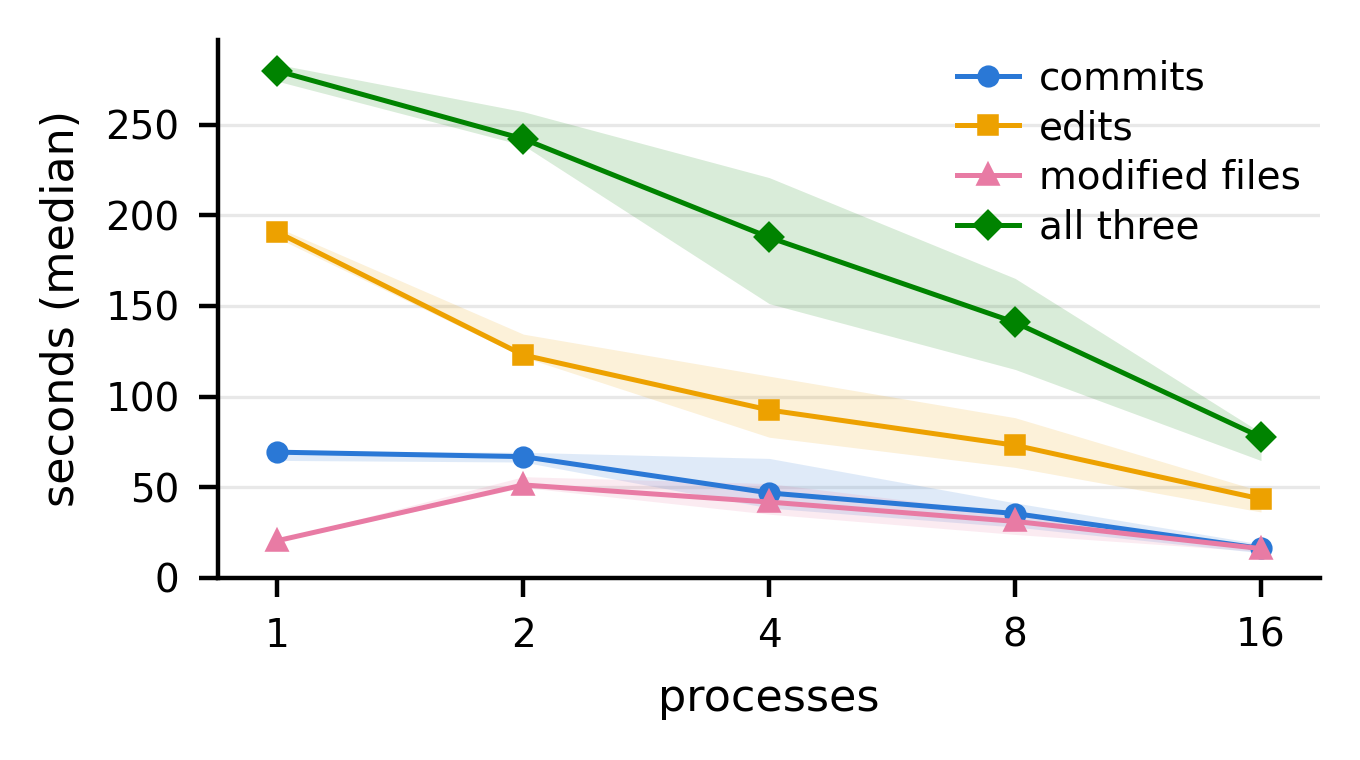

In [24]:
fig, left = plt.subplots(figsize=(3.5, 2), dpi=400)
processes = summary.index.to_numpy()

for stage in STAGES:
    color, med = STAGE_COLOR[stage], summary[(f"t_{stage}", "median")]
    left.fill_between(processes, summary[(f"t_{stage}", "min")],
                      summary[(f"t_{stage}", "max")], color=color, alpha=.15,
                      linewidth=0)
    left.plot(processes, med, color=color, marker=STAGE_MARKER[stage],
              markersize=3, linewidth=.9, label=STAGE_LABEL[stage])

left.set_xscale("log", base=2)
left.set_xticks(processes, [str(p) for p in processes])
left.set_xlabel("processes", fontsize=8)
left.set_ylabel("seconds (median)", fontsize=8)
left.tick_params(labelsize=7)
left.set_ylim(bottom=0)
left.grid(axis="y", color="#e8e8e8", linewidth=.6)
left.set_axisbelow(True)
for side in ("top", "right"):
    left.spines[side].set_visible(False)
left.margins(x=.06)
# Every curve falls as workers are added, so the upper right is the free corner
left.legend(frameon=False, loc="upper right", fontsize=7, labelspacing=.3,
            handlelength=1.6, handletextpad=.5, borderpad=0)

fig.tight_layout()
plt.savefig("performcance-analysis.pdf", bbox_inches="tight")
plt.show()